# Homework 6.1 - Steps 4, 5, and 9

## Causal Attention Predictor, Markov Comparison, and Context-Length Study

This notebook builds a small attention-based next-token predictor.

The model contains:

1. token embeddings;
2. positional information;
3. one causal self-attention layer;
4. a small feed-forward layer;
5. a softmax output over phase-space tokens.

Task 9 is included here because varying attention context length is part of the same training and model-selection workflow.

## Mathematical model

For a token context

$$
a_{i-L+1},\ldots,a_i,
$$

token embeddings and positional embeddings form

$$
h_j=E(a_j)+p_j.
$$

One causal attention head computes

$$
q_j=W_Qh_j,
\qquad
k_j=W_Kh_j,
\qquad
v_j=W_Vh_j.
$$

The attention score is

$$
s_{ij}
=
\frac{q_i^\top k_j}{\sqrt{d}},
$$

with the causal restriction

$$
j\le i.
$$

After softmax,

$$
A_{ij}
=
\frac{\exp(s_{ij})}
{\sum_{r\le i}\exp(s_{ir})}.
$$

The model predicts the next token from the representation at the final position of the context.

Training minimizes cross-entropy:

$$
L(\theta)
=
-\frac{1}{M}
\sum_i
\log
P_\theta(
a_{i+1}
\mid
a_{i-L+1},\ldots,a_i
).
$$

## Model-selection protocol

The candidate attention context lengths are fixed in advance:

$$
L\in\{4,8,16,32\}.
$$

All candidates use the same embedding size, feed-forward size, optimizer, and early-stopping rule.

The training split is used for gradient updates.

The validation split is used for:

- early stopping;
- selecting the attention context length.

Only after the attention context has been selected is the test split loaded for final evaluation.

In [13]:
from pathlib import Path
import json
import math
import random
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader

cwd = Path.cwd()
PROJECT_ROOT = cwd.parent if cwd.name.lower() == "codes" else cwd

DATA_DIR = PROJECT_ROOT / "data" / "hw6_1"
RESULT_DIR = PROJECT_ROOT / "result images" / "hw6_1"
TOKEN_DIR = DATA_DIR / "token_books"
MODEL_DIR = DATA_DIR / "attention_models"

MODEL_DIR.mkdir(parents=True, exist_ok=True)

config = json.loads(
    (
        DATA_DIR
        / "baseline_configuration.json"
    ).read_text(
        encoding="utf-8"
    )
)

VOCAB_SIZE = int(
    config["possible_vocabulary_size"]
)

SEED = 63864

CONTEXT_LENGTHS = [4, 8, 16, 32]

EMBED_DIM = 48
FF_DIM = 96
DROPOUT = 0.10

BATCH_SIZE = 256
MAX_EPOCHS = 10
PATIENCE = 2
LEARNING_RATE = 2e-3
WEIGHT_DECAY = 1e-5

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

print("Device:", DEVICE)
print("Vocabulary size:", VOCAB_SIZE)

Device: cuda
Vocabulary size: 1728


In [14]:
def load_token_books(split_name):
    books = []

    for path in sorted(
        (TOKEN_DIR / split_name).glob("book_*.csv")
    ):
        frame = pd.read_csv(path)

        books.append(
            frame["token"].to_numpy(
                dtype=np.int64
            )
        )

    if not books:
        raise FileNotFoundError(
            f"No token books found for split {split_name}. "
            "Run Steps 1-3 first."
        )

    return books


train_books = load_token_books("train")
validation_books = load_token_books("validation")

# The test split is deliberately not loaded yet.

print("Training books:", len(train_books))
print("Validation books:", len(validation_books))

Training books: 40
Validation books: 10


## Window dataset

Each example is built inside one trajectory book:

$$
(a_{i-L},\ldots,a_{i-1})
\longrightarrow
a_i.
$$

No attention context can cross a book boundary.

In [15]:
class TokenWindowDataset(Dataset):
    def __init__(self, books, context_length):
        self.books = [
            np.asarray(book, dtype=np.int64)
            for book in books
        ]

        self.context_length = int(
            context_length
        )

        self.index = []

        for book_index, sequence in enumerate(
            self.books
        ):
            for target_position in range(
                self.context_length,
                len(sequence),
            ):
                self.index.append(
                    (
                        book_index,
                        target_position,
                    )
                )

    def __len__(self):
        return len(self.index)

    def __getitem__(self, item):
        book_index, target_position = (
            self.index[item]
        )

        sequence = self.books[
            book_index
        ]

        start = (
            target_position
            - self.context_length
        )

        window = sequence[
            start:target_position
        ]

        target = sequence[
            target_position
        ]

        return (
            torch.as_tensor(
                window,
                dtype=torch.long,
            ),
            torch.tensor(
                int(target),
                dtype=torch.long,
            ),
        )

## Single-head causal self-attention

The complete lower-triangular causal mask is retained. This ensures the model never uses future tokens and allows the full attention matrix

$$
A_{ij}
$$

to be extracted later.

In [16]:
class SingleHeadCausalSelfAttention(nn.Module):
    def __init__(self, embed_dim, dropout):
        super().__init__()

        self.embed_dim = embed_dim

        self.query = nn.Linear(
            embed_dim,
            embed_dim,
            bias=False,
        )

        self.key = nn.Linear(
            embed_dim,
            embed_dim,
            bias=False,
        )

        self.value = nn.Linear(
            embed_dim,
            embed_dim,
            bias=False,
        )

        self.output = nn.Linear(
            embed_dim,
            embed_dim,
            bias=False,
        )

        self.dropout = nn.Dropout(
            dropout
        )

    def forward(
        self,
        x,
        return_weights=False,
    ):
        q = self.query(x)
        k = self.key(x)
        v = self.value(x)

        scores = (
            q
            @ k.transpose(-2, -1)
        ) / math.sqrt(
            self.embed_dim
        )

        length = x.shape[1]

        causal_mask = torch.triu(
            torch.ones(
                length,
                length,
                dtype=torch.bool,
                device=x.device,
            ),
            diagonal=1,
        )

        scores = scores.masked_fill(
            causal_mask,
            float("-inf"),
        )

        weights = torch.softmax(
            scores,
            dim=-1,
        )

        dropped_weights = self.dropout(
            weights
        )

        attended = dropped_weights @ v
        output = self.output(attended)

        if return_weights:
            return output, weights

        return output


class SmallCausalAttentionPredictor(nn.Module):
    def __init__(
        self,
        vocabulary_size,
        context_length,
        embed_dim,
        ff_dim,
        dropout,
    ):
        super().__init__()

        self.context_length = (
            context_length
        )

        self.token_embedding = nn.Embedding(
            vocabulary_size,
            embed_dim,
        )

        self.position_embedding = nn.Embedding(
            context_length,
            embed_dim,
        )

        self.attention = (
            SingleHeadCausalSelfAttention(
                embed_dim,
                dropout,
            )
        )

        self.norm1 = nn.LayerNorm(
            embed_dim
        )

        self.feed_forward = nn.Sequential(
            nn.Linear(
                embed_dim,
                ff_dim,
            ),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(
                ff_dim,
                embed_dim,
            ),
        )

        self.norm2 = nn.LayerNorm(
            embed_dim
        )

        self.output = nn.Linear(
            embed_dim,
            vocabulary_size,
        )

    def forward(
        self,
        tokens,
        return_attention=False,
    ):
        _, length = tokens.shape

        if length > self.context_length:
            raise ValueError(
                "Input sequence is longer than "
                "the configured context length."
            )

        positions = torch.arange(
            length,
            device=tokens.device,
        )

        x = (
            self.token_embedding(tokens)
            + self.position_embedding(
                positions
            )[None, :, :]
        )

        attention_output, weights = (
            self.attention(
                x,
                return_weights=True,
            )
        )

        x = self.norm1(
            x + attention_output
        )

        ff_output = self.feed_forward(
            x
        )

        x = self.norm2(
            x + ff_output
        )

        final_representation = x[
            :,
            -1,
            :,
        ]

        logits = self.output(
            final_representation
        )

        if return_attention:
            return logits, weights

        return logits


def count_parameters(model):
    return sum(
        parameter.numel()
        for parameter in model.parameters()
        if parameter.requires_grad
    )

# Task 4: train the attention predictor

In [17]:
def evaluate_attention(
    model,
    loader,
):
    model.eval()

    loss_function = nn.CrossEntropyLoss(
        reduction="sum"
    )

    total_loss = 0.0
    total_correct = 0
    total_examples = 0

    with torch.no_grad():
        for windows, targets in loader:
            windows = windows.to(DEVICE)
            targets = targets.to(DEVICE)

            logits = model(windows)

            total_loss += float(
                loss_function(
                    logits,
                    targets,
                ).item()
            )

            predictions = torch.argmax(
                logits,
                dim=1,
            )

            total_correct += int(
                (
                    predictions
                    == targets
                ).sum().item()
            )

            total_examples += int(
                targets.shape[0]
            )

    return {
        "nll": (
            total_loss
            / total_examples
        ),
        "accuracy": (
            total_correct
            / total_examples
        ),
        "examples": total_examples,
    }


def train_one_context(
    context_length,
):
    run_seed = (
        SEED
        + context_length
    )

    random.seed(run_seed)
    np.random.seed(run_seed)
    torch.manual_seed(run_seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(
            run_seed
        )

    train_dataset = TokenWindowDataset(
        train_books,
        context_length,
    )

    validation_dataset = TokenWindowDataset(
        validation_books,
        context_length,
    )

    train_loader = DataLoader(
        train_dataset,
        batch_size=BATCH_SIZE,
        shuffle=True,
        num_workers=0,
    )

    validation_loader = DataLoader(
        validation_dataset,
        batch_size=BATCH_SIZE,
        shuffle=False,
        num_workers=0,
    )

    model = SmallCausalAttentionPredictor(
        vocabulary_size=VOCAB_SIZE,
        context_length=context_length,
        embed_dim=EMBED_DIM,
        ff_dim=FF_DIM,
        dropout=DROPOUT,
    ).to(DEVICE)

    parameter_count = count_parameters(
        model
    )

    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=LEARNING_RATE,
        weight_decay=WEIGHT_DECAY,
    )

    loss_function = nn.CrossEntropyLoss()

    best_validation_nll = float("inf")
    best_validation_accuracy = 0.0
    best_state = None
    best_epoch = None
    epochs_without_improvement = 0

    start_time = time.perf_counter()

    for epoch in range(
        1,
        MAX_EPOCHS + 1,
    ):
        model.train()

        for windows, targets in train_loader:
            windows = windows.to(DEVICE)
            targets = targets.to(DEVICE)

            optimizer.zero_grad()

            logits = model(windows)

            loss = loss_function(
                logits,
                targets,
            )

            loss.backward()
            optimizer.step()

        validation_metrics = (
            evaluate_attention(
                model,
                validation_loader,
            )
        )

        print(
            f"L={context_length:>2} "
            f"epoch={epoch:>2} "
            f"val_nll="
            f"{validation_metrics['nll']:.5f} "
            f"val_acc="
            f"{validation_metrics['accuracy']:.5f}"
        )

        if (
            validation_metrics["nll"]
            < best_validation_nll
            - 1e-6
        ):
            best_validation_nll = (
                validation_metrics["nll"]
            )

            best_validation_accuracy = (
                validation_metrics[
                    "accuracy"
                ]
            )

            best_epoch = epoch

            best_state = {
                key: value.detach()
                .cpu()
                .clone()
                for key, value
                in model.state_dict().items()
            }

            epochs_without_improvement = 0

        else:
            epochs_without_improvement += 1

        if (
            epochs_without_improvement
            >= PATIENCE
        ):
            break

    elapsed = (
        time.perf_counter()
        - start_time
    )

    if best_state is None:
        raise RuntimeError(
            "No best model state was recorded."
        )

    checkpoint_path = (
        MODEL_DIR
        / (
            f"attention_context_"
            f"{context_length:02d}.pt"
        )
    )

    torch.save(
        {
            "state_dict": best_state,
            "context_length": (
                context_length
            ),
            "vocabulary_size": (
                VOCAB_SIZE
            ),
            "embed_dim": EMBED_DIM,
            "ff_dim": FF_DIM,
            "dropout": DROPOUT,
            "parameter_count": (
                parameter_count
            ),
            "best_epoch": (
                best_epoch
            ),
            "best_validation_nll": (
                best_validation_nll
            ),
            "best_validation_accuracy": (
                best_validation_accuracy
            ),
            "run_seed": run_seed,
        },
        checkpoint_path,
    )

    return {
        "context_length": (
            context_length
        ),
        "trainable_parameters": (
            parameter_count
        ),
        "best_epoch": (
            best_epoch
        ),
        "validation_nll": (
            best_validation_nll
        ),
        "validation_accuracy": (
            best_validation_accuracy
        ),
        "training_seconds": (
            elapsed
        ),
        "checkpoint": str(
            checkpoint_path.relative_to(
                PROJECT_ROOT
            )
        ),
    }

In [18]:
attention_validation_records = []

for context_length in CONTEXT_LENGTHS:
    print()
    print(
        "Training attention model "
        f"with L={context_length}"
    )

    record = train_one_context(
        context_length
    )

    attention_validation_records.append(
        record
    )


attention_validation = pd.DataFrame(
    attention_validation_records
)

validation_path = (
    DATA_DIR
    / "task4_5_9_attention_validation_results.csv"
)

attention_validation.to_csv(
    validation_path,
    index=False,
)

print()
print(attention_validation.to_string(index=False))
print()
print("Saved:", validation_path.resolve())


Training attention model with L=4
L= 4 epoch= 1 val_nll=1.05273 val_acc=0.70152
L= 4 epoch= 2 val_nll=0.76809 val_acc=0.74146
L= 4 epoch= 3 val_nll=0.69434 val_acc=0.75501
L= 4 epoch= 4 val_nll=0.65881 val_acc=0.76215
L= 4 epoch= 5 val_nll=0.64012 val_acc=0.76455
L= 4 epoch= 6 val_nll=0.62096 val_acc=0.76536
L= 4 epoch= 7 val_nll=0.61740 val_acc=0.76881
L= 4 epoch= 8 val_nll=0.61049 val_acc=0.77346
L= 4 epoch= 9 val_nll=0.60054 val_acc=0.76969
L= 4 epoch=10 val_nll=0.59878 val_acc=0.76889

Training attention model with L=8
L= 8 epoch= 1 val_nll=1.02957 val_acc=0.71078
L= 8 epoch= 2 val_nll=0.70711 val_acc=0.76283
L= 8 epoch= 3 val_nll=0.60851 val_acc=0.78713
L= 8 epoch= 4 val_nll=0.56373 val_acc=0.79960
L= 8 epoch= 5 val_nll=0.53359 val_acc=0.80282
L= 8 epoch= 6 val_nll=0.50520 val_acc=0.81247
L= 8 epoch= 7 val_nll=0.48283 val_acc=0.82076
L= 8 epoch= 8 val_nll=0.47656 val_acc=0.82317
L= 8 epoch= 9 val_nll=0.46128 val_acc=0.82727
L= 8 epoch=10 val_nll=0.48165 val_acc=0.81778

Training 

## Select the attention context using validation only

The primary selection metric is validation negative log-likelihood.

If two candidates tie numerically, the smaller context is preferred.

In [19]:
best_validation_nll = attention_validation[
    "validation_nll"
].min()

selected_attention_context = int(
    attention_validation[
        np.isclose(
            attention_validation[
                "validation_nll"
            ],
            best_validation_nll,
            rtol=0.0,
            atol=1e-8,
        )
    ]["context_length"].min()
)

selected_row = attention_validation[
    attention_validation["context_length"]
    == selected_attention_context
].iloc[0]

selection_record = {
    "selected_attention_context_length": (
        selected_attention_context
    ),
    "selection_metric": (
        "lowest validation negative log-likelihood"
    ),
    "validation_nll": float(
        selected_row[
            "validation_nll"
        ]
    ),
    "validation_accuracy": float(
        selected_row[
            "validation_accuracy"
        ]
    ),
    "candidate_context_lengths": (
        CONTEXT_LENGTHS
    ),
}

selection_path = (
    DATA_DIR
    / "task4_5_9_selected_attention_model.json"
)

selection_path.write_text(
    json.dumps(
        selection_record,
        indent=2,
    ),
    encoding="utf-8",
)

print(
    "Selected attention context L =",
    selected_attention_context,
)

print("Saved:", selection_path.resolve())

Selected attention context L = 32
Saved: C:\Users\benja\OneDrive\Univeristy of Alabama courses\Math 638\Project 2\HW6.1\data\hw6_1\task4_5_9_selected_attention_model.json


# Final held-out attention evaluation

The candidate contexts and validation selection rule are now fixed.

Only now is the test split loaded.

In [20]:
test_books = load_token_books("test")


def load_checkpoint_model(
    context_length,
):
    checkpoint_path = (
        MODEL_DIR
        / (
            f"attention_context_"
            f"{context_length:02d}.pt"
        )
    )

    checkpoint = torch.load(
        checkpoint_path,
        map_location=DEVICE,
    )

    model = SmallCausalAttentionPredictor(
        vocabulary_size=checkpoint[
            "vocabulary_size"
        ],
        context_length=checkpoint[
            "context_length"
        ],
        embed_dim=checkpoint[
            "embed_dim"
        ],
        ff_dim=checkpoint[
            "ff_dim"
        ],
        dropout=checkpoint[
            "dropout"
        ],
    ).to(DEVICE)

    model.load_state_dict(
        checkpoint["state_dict"]
    )

    model.eval()

    return model, checkpoint


attention_test_records = []

for context_length in CONTEXT_LENGTHS:
    model, checkpoint = (
        load_checkpoint_model(
            context_length
        )
    )

    test_dataset = TokenWindowDataset(
        test_books,
        context_length,
    )

    test_loader = DataLoader(
        test_dataset,
        batch_size=BATCH_SIZE,
        shuffle=False,
        num_workers=0,
    )

    metrics = evaluate_attention(
        model,
        test_loader,
    )

    attention_test_records.append({
        "context_length": (
            context_length
        ),
        "test_nll": (
            metrics["nll"]
        ),
        "test_accuracy": (
            metrics["accuracy"]
        ),
        "evaluated_positions": (
            metrics["examples"]
        ),
        "selected_by_validation": (
            context_length
            == selected_attention_context
        ),
    })


attention_test = pd.DataFrame(
    attention_test_records
)

test_path = (
    DATA_DIR
    / "task4_5_9_attention_test_results.csv"
)

attention_test.to_csv(
    test_path,
    index=False,
)

print(attention_test.to_string(index=False))
print()
print("Saved:", test_path.resolve())

 context_length  test_nll  test_accuracy  evaluated_positions  selected_by_validation
              4  0.570805       0.775140                12470                   False
              8  0.456078       0.826629                12430                   False
             16  0.416444       0.837976                12350                   False
             32  0.415362       0.839212                12190                    True

Saved: C:\Users\benja\OneDrive\Univeristy of Alabama courses\Math 638\Project 2\HW6.1\data\hw6_1\task4_5_9_attention_test_results.csv


# Task 5: compare attention with the Markov baseline

The final comparison uses the validation-selected model from each family.

In [21]:
markov_selection = json.loads(
    (
        DATA_DIR
        / "task3_selected_markov_baseline.json"
    ).read_text(
        encoding="utf-8"
    )
)

markov_test = pd.read_csv(
    DATA_DIR
    / "task3_markov_test_results.csv"
)

selected_markov_m = int(
    markov_selection[
        "selected_context_length_m"
    ]
)

markov_row = markov_test[
    markov_test["context_length_m"]
    == selected_markov_m
].iloc[0]

attention_row = attention_test[
    attention_test["context_length"]
    == selected_attention_context
].iloc[0]

comparison = pd.DataFrame([
    {
        "model": "Markov / m-gram",
        "selected_context": (
            selected_markov_m
        ),
        "test_accuracy": float(
            markov_row["accuracy"]
        ),
        "test_nll": np.nan,
    },
    {
        "model": "Causal attention",
        "selected_context": (
            selected_attention_context
        ),
        "test_accuracy": float(
            attention_row[
                "test_accuracy"
            ]
        ),
        "test_nll": float(
            attention_row[
                "test_nll"
            ]
        ),
    },
])

comparison_path = (
    DATA_DIR
    / "task5_attention_vs_markov.csv"
)

comparison.to_csv(
    comparison_path,
    index=False,
)

print(comparison.to_string(index=False))
print()
print("Saved:", comparison_path.resolve())

           model  selected_context  test_accuracy  test_nll
 Markov / m-gram                 3       0.758173       NaN
Causal attention                32       0.839212  0.415362

Saved: C:\Users\benja\OneDrive\Univeristy of Alabama courses\Math 638\Project 2\HW6.1\data\hw6_1\task5_attention_vs_markov.csv


# Task 9: does longer attention memory help?

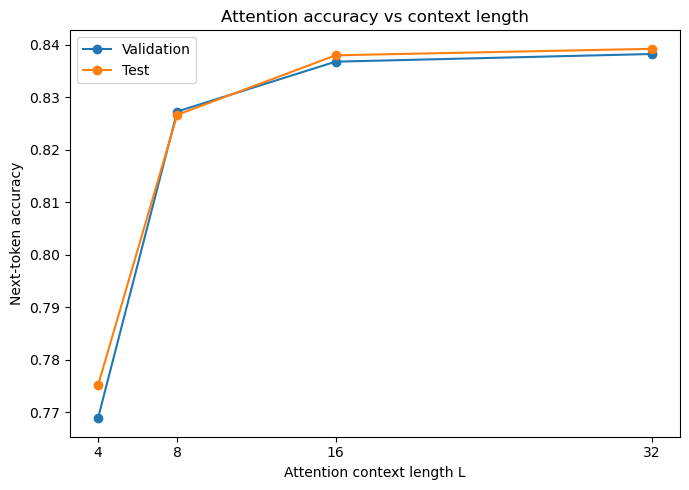

Saved: C:\Users\benja\OneDrive\Univeristy of Alabama courses\Math 638\Project 2\HW6.1\result images\hw6_1\step9_attention_accuracy_vs_context.png


In [22]:
merged = attention_validation.merge(
    attention_test,
    on="context_length",
    how="inner",
)

plt.figure(figsize=(7, 5))

plt.plot(
    merged["context_length"],
    merged["validation_accuracy"],
    marker="o",
    label="Validation",
)

plt.plot(
    merged["context_length"],
    merged["test_accuracy"],
    marker="o",
    label="Test",
)

plt.xlabel("Attention context length L")
plt.ylabel("Next-token accuracy")
plt.title("Attention accuracy vs context length")
plt.xticks(CONTEXT_LENGTHS)
plt.legend()
plt.tight_layout()

path = (
    RESULT_DIR
    / "step9_attention_accuracy_vs_context.png"
)

plt.savefig(
    path,
    dpi=200,
    bbox_inches="tight",
)

plt.show()

print("Saved:", path.resolve())

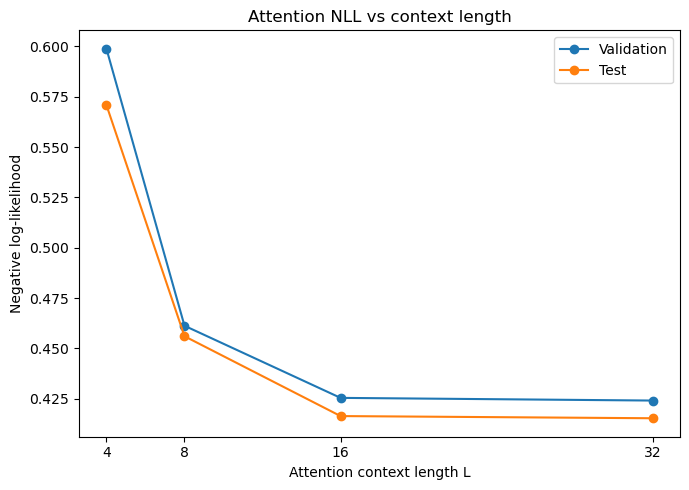

Saved: C:\Users\benja\OneDrive\Univeristy of Alabama courses\Math 638\Project 2\HW6.1\result images\hw6_1\step9_attention_nll_vs_context.png


In [23]:
plt.figure(figsize=(7, 5))

plt.plot(
    merged["context_length"],
    merged["validation_nll"],
    marker="o",
    label="Validation",
)

plt.plot(
    merged["context_length"],
    merged["test_nll"],
    marker="o",
    label="Test",
)

plt.xlabel("Attention context length L")
plt.ylabel("Negative log-likelihood")
plt.title("Attention NLL vs context length")
plt.xticks(CONTEXT_LENGTHS)
plt.legend()
plt.tight_layout()

path = (
    RESULT_DIR
    / "step9_attention_nll_vs_context.png"
)

plt.savefig(
    path,
    dpi=200,
    bbox_inches="tight",
)

plt.show()

print("Saved:", path.resolve())

## Interpretation rule

The correct conclusion must follow the measured validation/test curves.

A longer context is not automatically better. If validation NLL stops improving, that is evidence of diminishing or negative returns under the fixed training set and architecture.

The selected attention model is now fixed and will be used for Task 6 attention interpretation and Task 7 generation.

## Steps 4, 5, and 9 outputs

### Data

- `task4_5_9_attention_validation_results.csv`
- `task4_5_9_attention_test_results.csv`
- `task4_5_9_selected_attention_model.json`
- `task5_attention_vs_markov.csv`
- `attention_models/`

### Result images

- `step9_attention_accuracy_vs_context.png`
- `step9_attention_nll_vs_context.png`

## Audit correction: compare context lengths on common target positions

The native evaluations above begin at position `L`, so models with different context lengths are evaluated on slightly different target sets. This does **not** create train/test leakage, but it is a small comparability issue for Task 9.

For a strict like-for-like comparison, all candidate attention models are also evaluated on the common set of targets

$$
i\ge \max\{4,8,16,32\}=32.
$$

The same common target set is used for the selected Markov baseline when making the final Task 5 accuracy comparison. The audit recomputation gives the same model choice, so no retraining is required.

In [24]:
common_attention = pd.read_csv(
    DATA_DIR / "task9_attention_common_support_results.csv"
)

common_comparison = pd.read_csv(
    DATA_DIR / "task5_attention_vs_markov_common_support.csv"
)

print("Common-support attention results:")
print(common_attention.to_string(index=False))
print()
print("Common-support selected-model comparison:")
print(common_comparison.to_string(index=False))


Common-support attention results:
     split  context_length  common_start_position  evaluated_positions      nll  accuracy
validation               4                     32                12190 0.598656  0.768909
validation               8                     32                12190 0.460849  0.827564
validation              16                     32                12190 0.425505  0.836916
validation              32                     32                12190 0.424146  0.838228
      test               4                     32                12190 0.569040  0.775718
      test               8                     32                12190 0.454731  0.826743
      test              16                     32                12190 0.415905  0.838392
      test              32                     32                12190 0.415362  0.839212

Common-support selected-model comparison:
           model  selected_context  common_start_position  test_accuracy  test_nll
 Markov / m-gram              